# Confidence Interval Analysis: Air Quality Index (AQI)

## Project Objective
This project analyzes Air Quality Index (AQI) data across six US states to identify potential policy impacts and estimate the population mean AQI using a 95% confidence interval.

## Tools and Libraries
- Python
- Pandas
- NumPy
- Seaborn
- Matplotlib
- SciPy

In [4]:
# Import libraries for data analysis and visualization
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

# Load the AQI dataset
aqi = pd.read_csv(r"C:\Users\ankit\Desktop\Interview_docs\Statistics\c4_epa_air_quality.csv")

# Display the first five rows
aqi.head(5)

,date_local,state_name,county_name,city_name,local_site_name,parameter_name,units_of_measure,aqi_log
0,01-01-2018,Arizona,Maricopa,Buckeye,BUCKEYE,Carbon monoxide,Parts per million,2.079442
1,01-01-2018,Ohio,Belmont,Shadyside,Shadyside,Carbon monoxide,Parts per million,1.791759
2,01-01-2018,Wyoming,Teton,Not in a city,Yellowstone National Park - Old Faithful Snow ...,Carbon monoxide,Parts per million,1.098612
3,01-01-2018,Pennsylvania,Philadelphia,Philadelphia,North East Waste (NEW),Carbon monoxide,Parts per million,1.386294
4,01-01-2018,Iowa,Polk,Des Moines,CARPENTER,Carbon monoxide,Parts per million,1.386294


## Step 2: Data Exploration

Before performing statistical analysis, we will inspect the dataset's structure, time range, AQI values, and state-wise observations to understand the data we are working with.

In [18]:
# Check the dataset dimensions
print("Dataset shape:", aqi.shape)
print("==================================")
# Check column names and data types
aqi.info()

# Display summary statistics
display(aqi.describe(include="all"))

Dataset shape: (260, 8)
<class 'pandas.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   date_local        260 non-null    str    
 1   state_name        260 non-null    str    
 2   county_name       260 non-null    str    
 3   city_name         260 non-null    str    
 4   local_site_name   257 non-null    str    
 5   parameter_name    260 non-null    str    
 6   units_of_measure  260 non-null    str    
 7   aqi_log           260 non-null    float64
dtypes: float64(1), str(7)
memory usage: 38.0 KB


,date_local,state_name,county_name,city_name,local_site_name,parameter_name,units_of_measure,aqi_log
count,260,260,260,260,257,260,260,260.000000
unique,1,52,149,190,253,1,1,NaN
top,01-01-2018,California,Los Angeles,Not in a city,Kapolei,Carbon monoxide,Parts per million,NaN
freq,260,66,14,21,2,260,260,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.766921
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.714716
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.098612
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.791759
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.302585


In [17]:

# Check the date range
print("Start date:", aqi["date_local"].min())
print("End date:", aqi["date_local"].max())
print("==================================")
# Check minimum and maximum AQI
print("Minimum AQI:", aqi["aqi_log"].min())
print("Maximum AQI:", aqi["aqi_log"].max())
print("==================================")
# Count observations for each state
display(aqi["state_name"].value_counts().head(3))

Start date: 01-01-2018
End date: 01-01-2018
Minimum AQI: 0.0
Maximum AQI: 3.9318256327243257


state_name
California    66
Arizona       14
Ohio          12
Name: count, dtype: int64

## Step 3: State-Wise Mean AQI

Calculate the average Air Quality Index (AQI) for the six states where Ripple Renewable Energy (RRE) operates. We will compare these averages to identify which states have the highest mean AQI.

In [20]:
# Recover the original AQI values from the log-transformed column
aqi["aqi"] = np.exp(aqi["aqi_log"])

# Define the states where RRE operates
rre_states = [
    "California",
    "Florida",
    "Michigan",
    "Ohio",
    "Pennsylvania",
    "Texas"
]

# Filter the dataset for RRE states
rre_aqi = aqi[aqi["state_name"].isin(rre_states)].copy()

# Calculate and rank mean AQI by state
mean_aqi = (
    rre_aqi.groupby("state_name")["aqi"]
    .mean()
    .sort_values(ascending=False)
)

display(mean_aqi.round(2))

state_name
California      13.12
Michigan         9.11
Florida          6.50
Ohio             4.33
Pennsylvania     3.90
Texas            3.70
Name: aqi, dtype: float64


## 4. Identify States Meeting the Policy Threshold

The policy applies to states with a mean AQI of 10 or higher. We compare the mean AQI of the six RRE states against this threshold to identify which states meet the policy eligibility criterion.


In [21]:

# Identify states with mean AQI >= 10
eligible_states = mean_aqi[mean_aqi >= 10]

display(eligible_states.round(2))

state_name
California    13.12
Name: aqi, dtype: float64


### Interpretation

California is the only state among the six RRE states with a mean AQI of 10 or higher. Its mean AQI is 13.12, exceeding the policy threshold of 10. The remaining five states have mean AQI values below the threshold.


# -----------------------------------------------------------------------
## 5. Calculate a 95% Confidence Interval for California's Mean AQI

California has the highest mean AQI among the six RRE states, with a mean AQI of 13.12. Since its mean AQI exceeds the policy threshold of 10, we will calculate a 95% confidence interval to estimate the population mean AQI for California.

The confidence interval will help us understand the uncertainty associated with our sample mean estimate.


In [22]:

# Select AQI observations for California
ca_aqi = rre_aqi.loc[
    rre_aqi["state_name"] == "California", "aqi"
].dropna()

# Calculate sample statistics
n = ca_aqi.count()
sample_mean = ca_aqi.mean()
sample_std = ca_aqi.std()

print("Sample size:", n)
print("Sample mean AQI:", round(sample_mean, 2))
print("Sample standard deviation:", round(sample_std, 2))


Sample size: 66
Sample mean AQI: 13.12
Sample standard deviation: 7.3



### Interpretation

The sample size indicates the number of available AQI observations for California. The sample mean represents the average AQI, while the sample standard deviation measures the variability in AQI observations.

These statistics will be used to calculate the 95% confidence interval for California's population mean AQI.



## 6. Calculate the 95% Confidence Interval

We will calculate a 95% confidence interval for California's population mean AQI using the sample mean, sample standard deviation, and sample size.

Since the population standard deviation is unknown, we will use the t-distribution to calculate the confidence interval.

The confidence interval will provide a range of plausible values for California's population mean AQI.


In [24]:

from scipy import stats
import numpy as np

# Calculate the 95% confidence interval
confidence_level = 0.95
degrees_of_freedom = n - 1

t_critical = stats.t.ppf(
    (1 + confidence_level) / 2,
    degrees_of_freedom
)

standard_error = sample_std / np.sqrt(n)

margin_of_error = t_critical * standard_error

lower_bound = sample_mean - margin_of_error
upper_bound = sample_mean + margin_of_error

print("Standard Error:", round(standard_error, 2))
print("Margin of Error:", round(margin_of_error, 2))
print("95% Confidence Interval: (",
      round(lower_bound, 2), ",",
      round(upper_bound, 2), ")")


Standard Error: 0.9
Margin of Error: 1.79
95% Confidence Interval: ( 11.33 , 14.92 )



### Interpretation

The 95% confidence interval estimates a range of plausible values for California's population mean AQI. The margin of error represents the uncertainty around the sample mean estimate.


# ===================================================
## 7. Interpretation of the 95% Confidence Interval

The 95% confidence interval for California's population mean AQI is (11.33, 14.92), with a sample mean of 13.12 and a margin of error of 1.79.

This interval provides a range of plausible values for California's population mean AQI based on the sample data.

Importantly, the entire confidence interval lies above the policy threshold of 10. This suggests that California's population mean AQI may be above the threshold, assuming the sample is representative and the statistical assumptions are satisfied.


# ===================================================
## 8. Conclusion

The analysis compared mean AQI across the six RRE states: California, Florida, Michigan, Ohio, Pennsylvania, and Texas.

California had the highest mean AQI at 13.12 and was the only state with a sample mean AQI of at least 10.

The 95% confidence interval for California's population mean AQI was (11.33, 14.92). Since the entire interval is above 10, the findings provide statistical evidence that California's population mean AQI exceeds the policy threshold, subject to the representativeness of the sample and the assumptions of the confidence interval.

Further analysis would be needed to evaluate the effectiveness of the policy itself.



## 9. Compare AQI Distributions Across States

A boxplot is used to compare the distribution of AQI values across the six RRE states. It helps visualize the median, variability, and potential outliers in each state's AQI observations.

This comparison provides additional insight into how AQI values vary across states beyond their mean values.


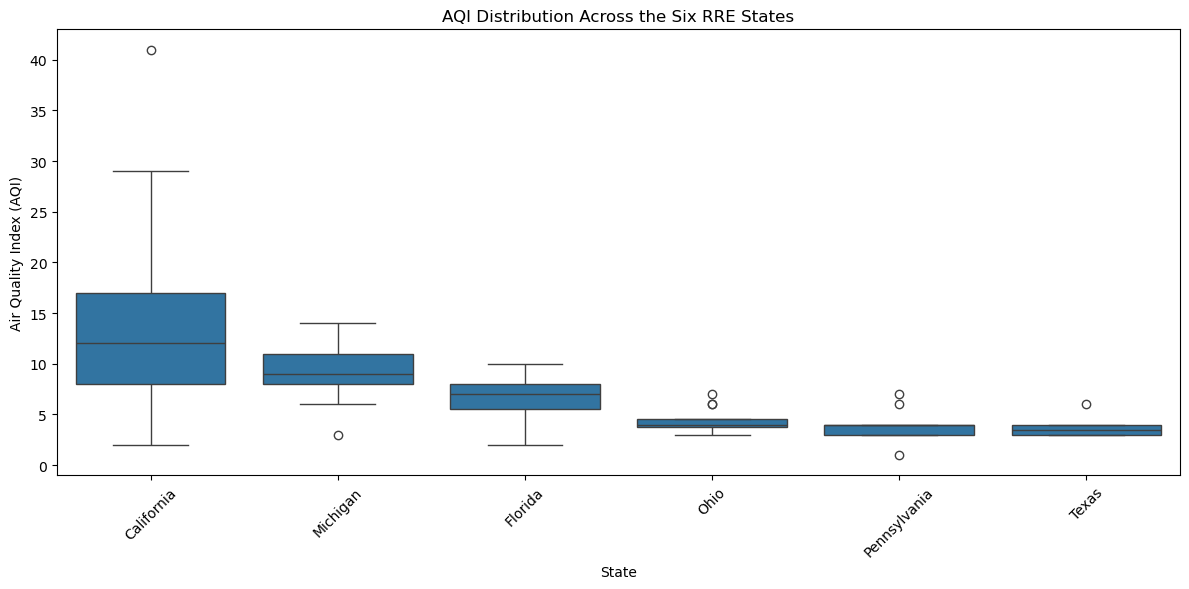

In [25]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=rre_aqi,
    x="state_name",
    y="aqi",
    order=mean_aqi.index
)

plt.title("AQI Distribution Across the Six RRE States")
plt.xlabel("State")
plt.ylabel("Air Quality Index (AQI)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



### Evaluation: Which State May Be Most Affected by the Policy?

California appears to be the state most affected by the policy based on the mean AQI results. It has the highest mean AQI of 13.12 among the six RRE states, exceeding the policy threshold of 10. The other five states have mean AQI values below this threshold.

The boxplot should be considered alongside the mean values to compare the states' medians, variability, and potential outliers. These distributional characteristics provide additional context about AQI patterns within each state.

Based on the mean AQI threshold, California is the only state that meets the stated eligibility criterion. However, the analysis identifies potential policy eligibility; it does not establish the policy's actual effect or effectiveness.



### Boxplot Interpretation

The boxplot compares the distribution of AQI values across the six states. The median line shows the central value of each distribution, while the box and whiskers illustrate the spread of the observations. Points beyond the whiskers may indicate potential outliers.

The plot complements the mean AQI comparison by showing differences in variability and distribution shape across states.



## 10. Key Findings and Recommendations

### Key Findings

- California had the highest mean AQI among the six RRE states, at 13.12.
- California was the only state with a sample mean AQI at or above the policy threshold of 10.
- The 95% confidence interval for California's population mean AQI was (11.33, 14.92).
- The boxplot provided a visual comparison of AQI distributions, including their medians, variability, and potential outliers.

### Recommendations

- Prioritize further investigation of air quality conditions in California because its sample mean AQI exceeds the policy threshold.
- Use the boxplot and descriptive statistics together to understand differences in AQI distributions across states.
- Evaluate the policy's effectiveness using additional evidence and an appropriate study design rather than relying only on mean AQI and a confidence interval.
